In [2]:
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F
%matplotlib inline
words = open('../names.txt', 'r').read().splitlines()
char = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(char)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [88]:
block_size = 8
def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))
Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xv, Yv = build_dataset(words[n1:n2])   # 10%
Xt,  Yt  = build_dataset(words[n2:])     # 10%

In [114]:
class Linear:
    def __init__(self, fan_in, fan_out, bias=True):
        self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # note: kaiming init
        self.bias = torch.zeros(fan_out) if bias else None
  
    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out
  
    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class BatchNorm1d:
    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters (trained with backprop)
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)
        # buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)
  
    def __call__(self, x):
    # calculate the forward pass
        if self.training:
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3: # support (B, T, C) batch of sequences, normalize over B and T
                dim = (0,1)
            xmean = x.mean(dim, keepdim=True) # batch mean
            xvar = x.var(dim, keepdim=True) # batch variance
        else:
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x - xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
        self.out = self.gamma * xhat + self.beta
        # update the buffers
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out
  
    def parameters(self):
        return [self.gamma, self.beta]


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

class Embedding:
    def __init__(self, num_embeddings, embedding_dim):
        self.weight = torch.randn((num_embeddings, embedding_dim)) # this weight is the c we used!

    def __call__(self, ix):
        self.out = self.weight[ix]
        return self.out
    def parameters(self):
        return [self.weight]

class Flatten:
    def __call__(self, x):
        self.out = x.view(x.shape[0], -1)
        return self.out
    def parameters(self):
        return []

#A bottleneck in how neural networks learn patterns. Going straight to (27, 80) from (27, 8, 10) squashes the entire context together all at once, 
# whereas going through intermediate steps like (27, 4, 20) creates a hierarchical tree structure (often called a WaveNet structure).
class FlattenConsecutive:
    def __init__(self, n):
        self.n = n      #n is the number of consecutive elements you want to merge together
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T//self.n, C*self.n)    # The new sequence length becomes T divided by n (T // n) and The new feature size becomes C multiplied by n (C * n).
        # Optimization: If the sequence length (T) is reduced down to exactly 1, squeeze out that dimension to convert the 3D tensor (B, 1, New_C) into a 2D tensor (B, New_C).
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out
    def parameters(self):
        return []

class Sequential:
    def __init__(self, layers): # takes the dict of layer.
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers: # for each layer, we will pass the input x through it and it sends out the input to the next layer which is a activation function.
            x = layer(x)
            self.out = x
        return self.out
    def parameters(self):
        return [p for l in self.layers for p in l.parameters()]

In [122]:
embedding_size = 24
hidden_size = 128
# C = torch.randn((27, embedding_size))  we made embedding a class instead of a parameter, so we don't need this anymore

#layers = [
#    Embedding(len(stoi), embedding_size), # now C is a weight matrix inside the Embedding class
#    Flatten(), # used to flatten the 3D tensor into a 2D tensor for the Linear layer
#    Linear(embedding_size * block_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
#    Linear(hidden_size, len(stoi))]
#model = Sequential([
#    Embedding(len(stoi), embedding_size), Flatten(),
#    Linear(embedding_size * block_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
#    Linear(hidden_size, len(stoi))
#])
model = Sequential([
    Embedding(len(stoi), embedding_size), 
    FlattenConsecutive(2), Linear(embedding_size * 2, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    FlattenConsecutive(2), Linear(hidden_size * 2, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    FlattenConsecutive(2), Linear(hidden_size * 2, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, len(stoi))
])

with torch.no_grad():
    model.layers[-1].weight *= 0.1 # making last layer smaller (less confident)

# parameters = [C] + [p for layer in layers for p in layer.parameters()] 
parameters = model.parameters()
print(sum(p.nelement() for p in parameters))
for p in parameters:
    p.requires_grad = True

76579


In [123]:
batch_size = 32
lossi = []
for i in range(200000):
    ix = torch.randint(0, Xtr.shape[0], (batch_size,))
    Xb, Yb = Xtr[ix], Ytr[ix]
    #emb = C[Xb]
    #x = emb.view(emb.shape[0], -1) done in the Flatten class, so we don't need this anymore
    #x = Xb # still need to pass the input through the layers
    #for layer in layers:
    #    x = layer(x)                   don't enev need to do this anymore, we can just call the model directly it will put the input through all the layers
    x = model(Xb)
    loss = F.cross_entropy(x, Yb)
    for p in parameters:
        p.grad = None
    loss.backward()
    lr = 0.1 if i < 100000 else 0.01
    for p in parameters:
        p.data += -lr * p.grad

    if i % 10000 == 0:
        print(f"{i:7d}: {loss.item():.4f}")
    lossi.append(loss.log10().item())
    #if i == 100000:break
    

      0: 3.2997
  10000: 1.8100
  20000: 2.2864
  30000: 1.8325
  40000: 1.5214
  50000: 1.7223
  60000: 1.8558
  70000: 1.8530
  80000: 1.7753
  90000: 2.1049
 100000: 1.7667
 110000: 1.5319
 120000: 1.6177
 130000: 1.6339
 140000: 1.9374
 150000: 1.5385
 160000: 1.9995
 170000: 1.8176
 180000: 1.7052
 190000: 1.3315


In [124]:
for layer in model.layers:
    print(layer.__class__.__name__, ':', tuple(layer.out.shape)) # the output of each layer.

Embedding : (32, 8, 24)
FlattenConsecutive : (32, 4, 48)
Linear : (32, 4, 128)
BatchNorm1d : (32, 4, 128)
Tanh : (32, 4, 128)
FlattenConsecutive : (32, 2, 256)
Linear : (32, 2, 128)
BatchNorm1d : (32, 2, 128)
Tanh : (32, 2, 128)
FlattenConsecutive : (32, 256)
Linear : (32, 128)
BatchNorm1d : (32, 128)
Tanh : (32, 128)
Linear : (32, 27)


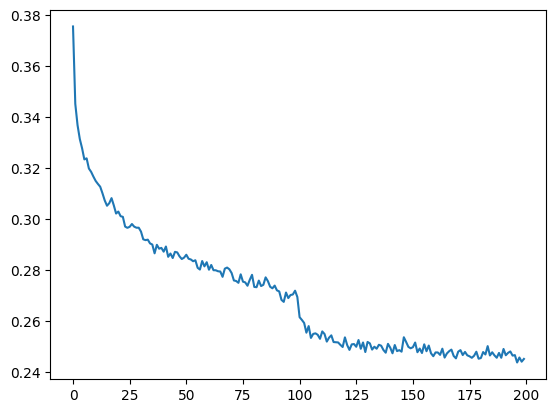

In [125]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1)) # taking mean along the rows, so we get 20 points instead of 20000 points, which is easier to visualize

In [126]:
#for layer in layers: # putting layers in eval mode 
#    layer.training = False
for layer in model.layers:
    layer.training = False
# evaluate the loss 
@torch.no_grad()
def split_loss(split):
    x, y = {
        'train': (Xtr, Ytr),
        'val': (Xv, Yv),
        'test': (Xt, Yt)
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())
split_loss('train')
split_loss('val')
split_loss('test')

train 1.7443246841430664
val 2.235809564590454
test 2.280515193939209


In [127]:
for _ in range(20):
    out = []
    context = [0] * block_size
    while True:
        #emb = C[torch.tensor([context])]
        #x = emb.view(emb.shape[0], -1)
        #for layer in layers:
        #    x = layer(x)
        logits = model(torch.tensor([context]))
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))

avareen.
jahlani.
kaasir.
cotton.
reetsy.
chaceann.
jarya.
bridgett.
saydie.
zignia.
briella.
donav.
heba.
sahirah.
milyne.
stefanio.
khalix.
javeyah.
seriana.
zerae.


#performance log

    original (4 character context + 200 hidden neurons, 12K params): train 1.9996812, val 2.0609893
    context: 4 -> 8 (22K params): train 1.918, val 2.027
    context: 8 -> 24 (70k params): train 1.7443246841430664, val 2.235809564590454, test 2.280515193939209
